## Data Mining Project ##
### Predicting Flowers Types Using Supervised Machine Learning Model - Classification: Logistic Regression and Decision Tree Methods
### Jean Tinialaou ###


## 1. How does your data-set look like? what are the dependent attributes and what is the class you want ##
## to predict? Did you obtain any statistics from your data-set? ##

Our dataset (Iris.csv) is short containing 150 entries. There are no null values. Therefore, dataset is clean. It just needs features engineering. Dependent attributes are sepallengthCM, sepalwidthCm, petallengthCm, petalwidthCm aolng with target variable 'species'. Since the dataset is short, our satisfaction is less versy if data was larger.
## 2. What were the pre-processing steps you performed? Why? ##
We called LabelEncoder of preprocessing class from sklean to convert categoricals to numericals

## 3. Explain which classification algorithm you used and why ##
We are using logistic regression and decision tree machine learning models. 

## 4 Explain how you built the models and how hyperparameters are selected ##
We built the models by training data splitting 80% train and 20% test

## 5. Explain your method for model evaluation How do the two models compare? ##
Our metrics are almost similar with accuracy 1.0, precison 1.0, reall 1.0 across all train and test datasets within both logistic regression and decision tree classifications, leading to overfitting. This happens due to the short dataset in our DataFrame.


## Using Logistic Regression Method ##

In [2]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import precision_score, recall_score

In [5]:
df = pd.read_csv("Iris.csv")

In [6]:
#Exploring Data
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [9]:
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [10]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [11]:
df.describe(include = "object")

,Species
count,150
unique,3
top,Iris-setosa
freq,50


In [12]:
df['Species'].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Species        Iris-setosa  Iris-versicolor  Iris-virginica
SepalLengthCm                                              
4.3                      1                0               0
4.4                      3                0               0
4.5                      1                0               0
4.6                      4                0               0
4.7                      2                0               0
4.8                      5                0               0
4.9                      4                1               1
5.0                      8                2               0
5.1                      8                1               0
5.2                      3                1               0
5.3                      1                0               0
5.4                      5                1               0
5.5                      2                5               0
5.6                      0                5               1
5.7                      2              

<Axes: xlabel='SepalLengthCm'>

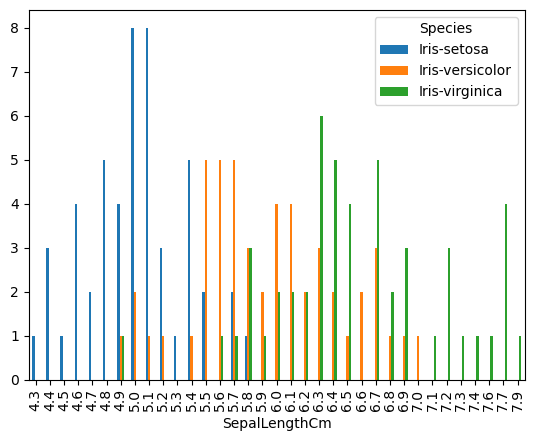

In [14]:
#Visualization

SepalLengthCm=pd.crosstab(df['SepalLengthCm'],df['Species'])
print(SepalLengthCm)
SepalLengthCm.plot(kind='bar')

Species       Iris-setosa  Iris-versicolor  Iris-virginica
SepalWidthCm                                              
2.0                     0                1               0
2.2                     0                2               1
2.3                     1                3               0
2.4                     0                3               0
2.5                     0                4               4
2.6                     0                3               2
2.7                     0                5               4
2.8                     0                6               8
2.9                     1                7               2
3.0                     6                8              12
3.1                     5                3               4
3.2                     5                3               5
3.3                     2                1               3
3.4                     9                1               2
3.5                     6                0              

<Axes: xlabel='SepalWidthCm'>

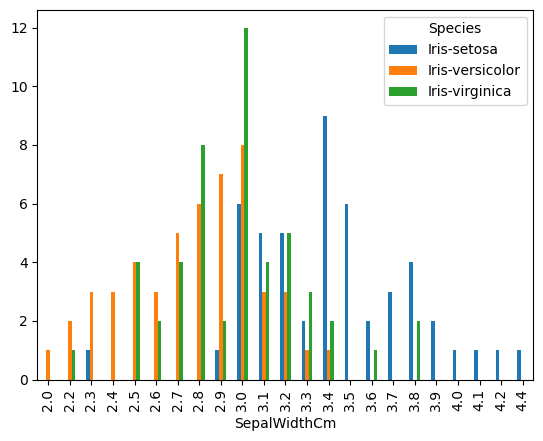

In [15]:
SepalWidthCm=pd.crosstab(df['SepalWidthCm'],df['Species'])
print(SepalWidthCm)
SepalWidthCm.plot(kind='bar')

Species        Iris-setosa  Iris-versicolor  Iris-virginica
PetalLengthCm                                              
1.0                      1                0               0
1.1                      1                0               0
1.2                      2                0               0
1.3                      7                0               0
1.4                     12                0               0
1.5                     14                0               0
1.6                      7                0               0
1.7                      4                0               0
1.9                      2                0               0
3.0                      0                1               0
3.3                      0                2               0
3.5                      0                2               0
3.6                      0                1               0
3.7                      0                1               0
3.8                      0              

<Axes: xlabel='PetalLengthCm'>

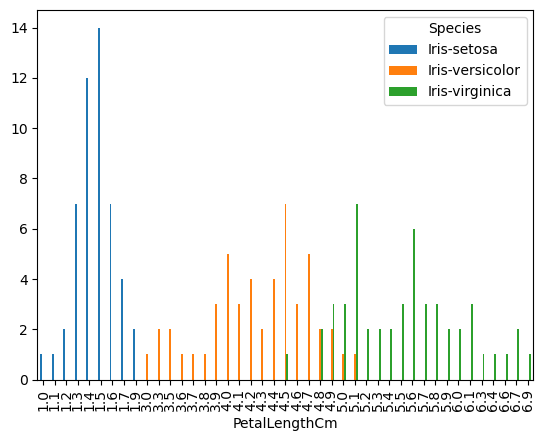

In [16]:
PetalLengthCm=pd.crosstab(df['PetalLengthCm'],df['Species'])
print(PetalLengthCm)
PetalLengthCm.plot(kind='bar')

Species       Iris-setosa  Iris-versicolor  Iris-virginica
PetalWidthCm                                              
0.1                     6                0               0
0.2                    28                0               0
0.3                     7                0               0
0.4                     7                0               0
0.5                     1                0               0
0.6                     1                0               0
1.0                     0                7               0
1.1                     0                3               0
1.2                     0                5               0
1.3                     0               13               0
1.4                     0                7               1
1.5                     0               10               2
1.6                     0                3               1
1.7                     0                1               1
1.8                     0                1              

<Axes: xlabel='PetalWidthCm'>

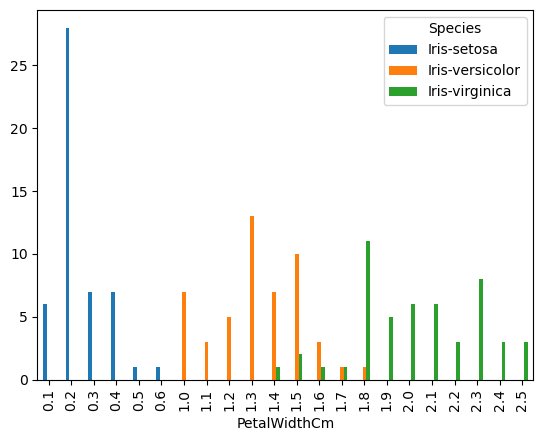

In [17]:
PetalWidthCm=pd.crosstab(df['PetalWidthCm'],df['Species'])
print(PetalWidthCm)
PetalWidthCm.plot(kind='bar')

Species       Iris-setosa  Iris-versicolor  Iris-virginica
PetalWidthCm                                              
0.1                     6                0               0
0.2                    28                0               0
0.3                     7                0               0
0.4                     7                0               0
0.5                     1                0               0
0.6                     1                0               0
1.0                     0                7               0
1.1                     0                3               0
1.2                     0                5               0
1.3                     0               13               0
1.4                     0                7               1
1.5                     0               10               2
1.6                     0                3               1
1.7                     0                1               1
1.8                     0                1              

<Axes: xlabel='PetalWidthCm'>

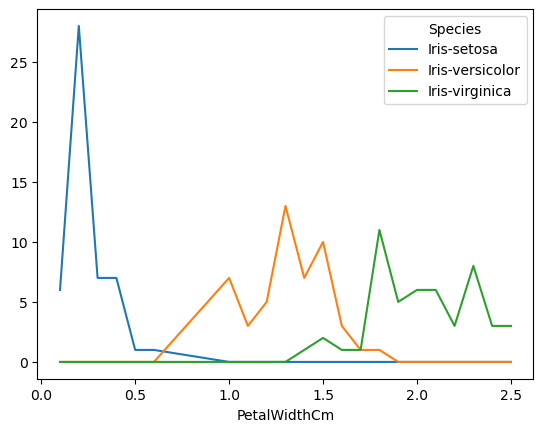

In [20]:
PetalWidthCm=pd.crosstab(df['PetalWidthCm'],df['Species'])
print(PetalWidthCm)
PetalWidthCm.plot(kind='line')

In [21]:
# Splitting Data into train and test sets
from sklearn.model_selection import train_test_split
X = df.drop("Species", axis=1)
Y = df["Species"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=30)
print(X_train.shape, Y_train.shape)
print(X_test.shape, Y_test.shape)


(120, 5) (120,)
(30, 5) (30,)


In [32]:
# Preprocessing Data
from sklearn.preprocessing import LabelEncoder
# seperating Encoder for every column
encoder_Species = LabelEncoder()
encoder_train = LabelEncoder()

In [35]:
# define our regression model
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

# train our model
model.fit(X_train, Y_train)
print('Model Trained')

Model Trained


C:\Users\jeant\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [36]:
# check our model score
print('Model score {}'.format(model.score(X_test, Y_test)))

Model score 1.0


In [40]:
# check precison and recall values
from sklearn.metrics import precision_score, recall_score
y_pred = model.predict(X_test)
precision = precision_score(Y_test, y_pred, average='weighted')
print("Precision:", precision)
recall = recall_score(Y_test, y_pred, average='weighted')
print("Recall:", recall)

Precision: 1.0
Recall: 1.0


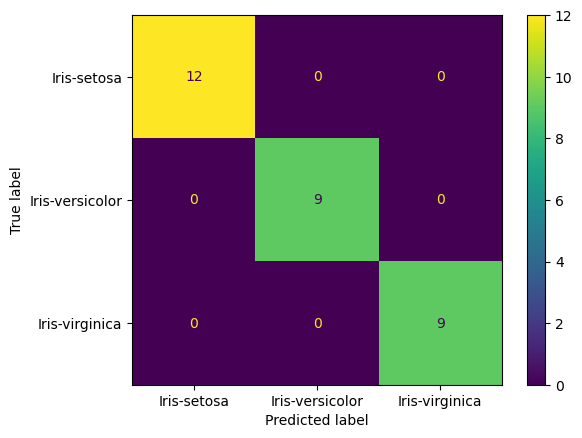

In [43]:
# get and plot the confusion matrix
import matplotlib.pyplot as plt
from sklearn import metrics
confusion_matrix = metrics.confusion_matrix(Y_test, y_pred)
unique_classes = sorted(list(set(Y_test) | set(y_pred)))
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels=unique_classes)

cm_display.plot()
plt.show()

## Using Decision Tree Method ##

In [5]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score

In [6]:
# loading Data
df = pd.read_csv("Iris.csv")

In [7]:
# Exploring Data
rows = df.shape[0]
columns = df.shape[1]

print("There are {} rows and {} columns".format(rows,columns))

There are 150 rows and 6 columns


In [8]:
# Double-checking for any missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [9]:
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

## Transforming Data ##


In [10]:
# Creating a target column based on Species column
species_to_target = {'Iris-setosa':0, 'Iris-versicolor': 1, 'Iris-virginica': 2}

In [11]:
# Add the target column
df['target'] = df['Species'].map(species_to_target)
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,target
0,1,5.1,3.5,1.4,0.2,Iris-setosa,0
1,2,4.9,3.0,1.4,0.2,Iris-setosa,0
2,3,4.7,3.2,1.3,0.2,Iris-setosa,0
3,4,4.6,3.1,1.5,0.2,Iris-setosa,0
4,5,5.0,3.6,1.4,0.2,Iris-setosa,0


## Preparing Data for Modeling ##

In [12]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# encode target
encoder_target = LabelEncoder()
Y = encoder_target.fit_transform(df["target"])

# drop Id columns
df = df.drop(columns=['Id'], errors="ignore")

In [13]:
# define X and Y
X = df.drop(columns=["Species"])
Y = df["Species"]

# feature column
X = df.drop("target", axis=1)

In [14]:
# check for cat column
categorical_cols = X.select_dtypes(include=['object']).columns
for col in categorical_cols:
    encoder = LabelEncoder()
    X[col] = encoder.fit_transform(X[col])

In [15]:
# Splititing Data
X_train, X_test, Y_train, Y_test = train_test_split( X, Y, test_size=0.25, random_state=50)

In [16]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier()

# train our model
model.fit(X_train, Y_train)
print('Model Trained')

Model Trained


[Text(0.4, 0.8333333333333334, 'PetalLengthCm <= 2.6\ngini = 0.666\nsamples = 112\nvalue = [39, 35, 38]\nclass = setosa'),
 Text(0.2, 0.5, 'gini = 0.0\nsamples = 39\nvalue = [39, 0, 0]\nclass = setosa'),
 Text(0.30000000000000004, 0.6666666666666667, 'True  '),
 Text(0.6, 0.5, 'Species <= 1.5\ngini = 0.499\nsamples = 73\nvalue = [0, 35, 38]\nclass = virginica'),
 Text(0.5, 0.6666666666666667, '  False'),
 Text(0.4, 0.16666666666666666, 'gini = 0.0\nsamples = 35\nvalue = [0, 35, 0]\nclass = versicolor'),
 Text(0.8, 0.16666666666666666, 'gini = 0.0\nsamples = 38\nvalue = [0, 0, 38]\nclass = virginica')]

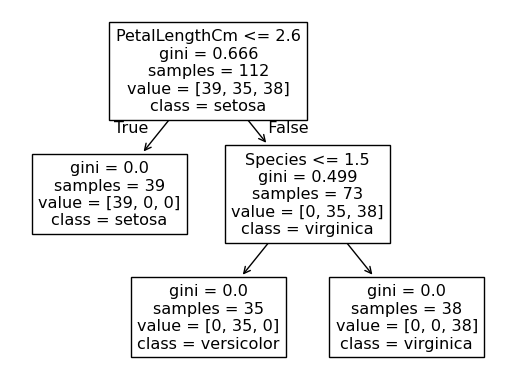

In [17]:
from sklearn import tree
tree.plot_tree(model, feature_names=X.columns, class_names=['setosa', 'versicolor', 'virginica'])

In [18]:
import numpy as np
features = np.array([0.5,0,1,1,0])

results = model.predict([features])
print("This flower is of type:", results)

This flower is of type: ['Iris-setosa']


C:\Users\jeant\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


## Metrics Evaluation ##

In [26]:
# check accuracy,  precison, and recall values
from sklearn.metrics import accuracy_score, precision_score, recall_score
y_pred = model.predict(X_test)

print("Train data accuracy:", accuracy_score(y_true = Y_train, y_pred=model.predict(X_train)))
print("Test data accuracy:", accuracy_score(y_true = Y_test, y_pred=y_pred))

print("Train data precision:", precision_score(y_true = Y_train, y_pred=model.predict(X_train), average='micro'))
print("Test data precision:", precision_score(y_true = Y_test, y_pred=y_pred, average='micro'))

print("Train data recall:", recall_score(y_true = Y_train, y_pred=model.predict(X_train), average='micro'))
print("Test data recall:", recall_score(y_true = Y_test, y_pred=y_pred, average='micro'))


Train data accuracy: 1.0
Test data accuracy: 1.0
Train data precision: 1.0
Test data precision: 1.0
Train data recall: 1.0
Test data recall: 1.0


### Output Analysis ###
#### Accuracy:
        Train: 1.0 (100%)
        Test: 1.0 (100%)
        This metrics shows the model performed well on both training and test datasets, leading to a good learning and generalization. But it suggests an overfitting

#### Precision: 
          Train: 1.0 (100%)
          Test: 1.0 (100%)
          High precision tells the model's positive predictions are correct with respecct to the actual, leading a consistency.

#### Recall:
       Train: 1.0 (100%) 
       Test: 1.0 (100%)
       High recall indicates the model identifies all true positive cases correctly 